# Customer Churn Prediction: Exploratory Data Analysis

## Project Overview

The goal of this project is to analyze customer data and develop machine learning models that predict customer churn.

Customer churn occurs when a customer stops using a company's products or services. Understanding the factors associated with churn can help businesses identify customers who may be at risk of leaving and develop targeted retention strategies.

## Objectives

- Explore customer demographics and account information
- Identify patterns and relationships associated with churn
- Examine missing values, data types, and potential quality issues
- Identify features that may be useful for predicting churn

In [11]:
# data manipulation
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# display settings
pd.set_option('display.max_columns', None)

# visualization settings
sns.set_style('whitegrid')

# make plots display inside the notebook
%matplotlib inline

### 1. Loading the Dataset

The first step in exploratory data analysis is loading the dataset and becoming familiar with its structure.

This project uses the IBM Telco Customer Churn dataset, which contains customer account information, subscribed services, billing information, and customer churn status.

Pandas is used to load the CSV file into a DataFrame, allowing us to inspect, clean, and analyze the data throughout the project.

The initial inspection will help us understand the dataset's size, available features, and overall data quality.

In [12]:
from pathlib import Path

# locate the dataset whether Jupyter starts in the project
# root directory or in the notebooks directory
data_path = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not data_path.exists():
    data_path = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
    
# load the dataset
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
# display the first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2. Initial Data Inspection

Before performing any analysis, it is important to understand the structure and quality of the dataset.

Several checks are performed:

- Dataset dimensions identify the number of customer records and available features
- Data types help identify numerical and categorical variables
- Missing-value checks identify incomplete records
- Duplicate checks help identify repeated observations
- Summary statistics provide an initial understanding of numerical feature distributions

These checks help identify potential data-cleaning requirements before mocing into deeper analysis.

In [14]:
# display the number of rows and columns in the dataset
print(f"The dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")

# display column names and their data types
print("\nColumn names:")
print(df.columns.tolist())

# display data types and non-null counts for each column
print("\nData information:")
print(df.info())

The dataset contains 7043 rows and 21 columns.

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetServi

In [15]:
# generate descriptive statistics for numerical columns
print("\nDescriptive statistics for numerical columns:")
print(df.describe())

# generate descriptive statistics for all columns
print("\nDescriptive statistics for all columns:")
print(df.describe(include='all'))


Descriptive statistics for numerical columns:
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000

Descriptive statistics for all columns:
        customerID gender  SeniorCitizen Partner Dependents       tenure  \
count         7043   7043    7043.000000    7043       7043  7043.000000   
unique        7043      2            NaN       2          2          NaN   
top     7590-VHVEG   Male            NaN      No         No          NaN   
freq             1   3555            NaN    3641       4933          NaN   
mean           NaN    NaN       0.162147     NaN        NaN    32.371149   
std   

In [16]:
# check for missing values in each column
missing_values = df.isnull().sum()

print("\nMissing values in each column:")
print(missing_values[missing_values > 0])

# check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# check unique values in each column
for column in df.columns:
    unique_values = df[column].nunique()
    print(f"Column '{column}' has {unique_values} unique values.")


Missing values in each column:
Series([], dtype: int64)
Duplicate rows: 0
Column 'customerID' has 7043 unique values.
Column 'gender' has 2 unique values.
Column 'SeniorCitizen' has 2 unique values.
Column 'Partner' has 2 unique values.
Column 'Dependents' has 2 unique values.
Column 'tenure' has 73 unique values.
Column 'PhoneService' has 2 unique values.
Column 'MultipleLines' has 3 unique values.
Column 'InternetService' has 3 unique values.
Column 'OnlineSecurity' has 3 unique values.
Column 'OnlineBackup' has 3 unique values.
Column 'DeviceProtection' has 3 unique values.
Column 'TechSupport' has 3 unique values.
Column 'StreamingTV' has 3 unique values.
Column 'StreamingMovies' has 3 unique values.
Column 'Contract' has 3 unique values.
Column 'PaperlessBilling' has 2 unique values.
Column 'PaymentMethod' has 4 unique values.
Column 'MonthlyCharges' has 1585 unique values.
Column 'TotalCharges' has 6531 unique values.
Column 'Churn' has 2 unique values.


### 3. Understanding the Target Variable

The target variable for this project is 'Churn', which indicates whether a customer discontinued their service.

Understanding the distribution of the target variable is important because it reveals whether the classification problem has balanced or imbalanced classes.

If one class occurs significantly more often than another, a model may favor predicting the majority class.

This analysis will help determine which evaluation metrics should be prioritized when comparing machine learning models.

In [17]:
# count customers in each churn category
churn_counts = df['Churn'].value_counts()

print("\nCustomer counts in each churn category:")
print(churn_counts)

# calculate churn percentages
churn_percentages = df['Churn'].value_counts(normalize=True) * 100

print("\nChurn percentages:")
print(churn_percentages.round(2))


Customer counts in each churn category:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### 4. Numerical Feature Analysis

The numerical features provide information about customer tenure and billing behavior.

The following features are examined:

- 'tenure': Number of months the customer has remained with the company
- 'MonthlyCharges': The customer's monthly service charges
- 'TotalCharges': The total amount charged to the customer

Histograms are used to examine the distribution of these features, while box plots help identify potential outliers and compare the spread of values.

These visualizations can reveal patterns in customer behavior and help identify numerical features that my be useful for predicting churn.

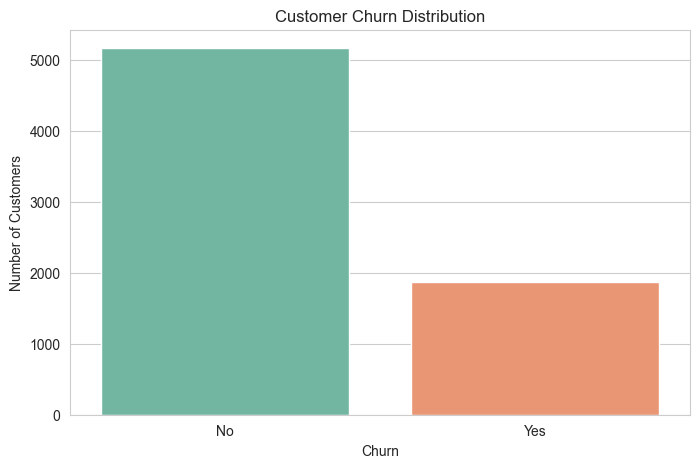

In [18]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

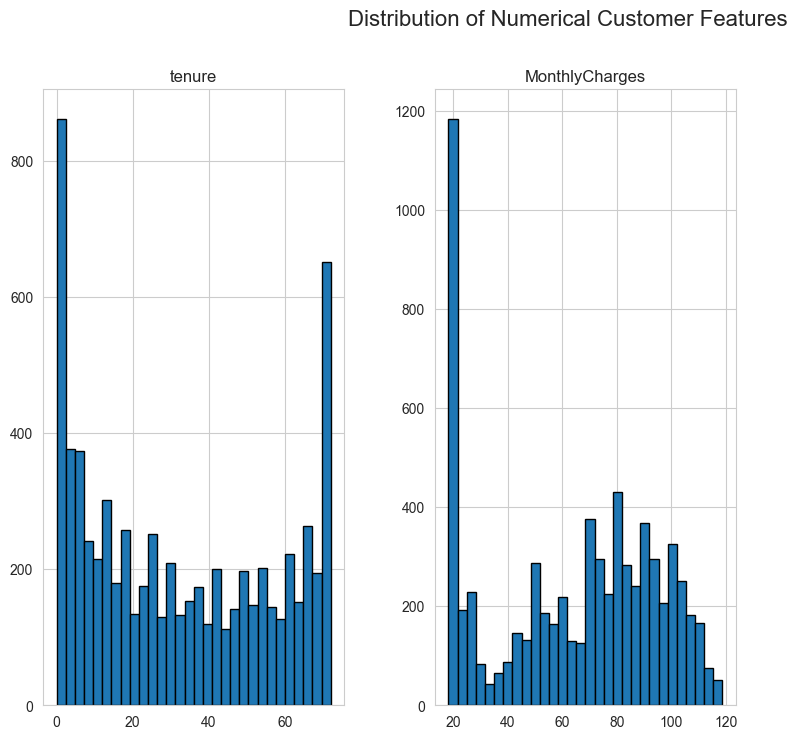

In [19]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_features].hist(
    bins=30,
    figsize=(14, 8),
    layout=(1, 3),
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Customer Features", fontsize=16)

plt.tight_layout
plt.show()

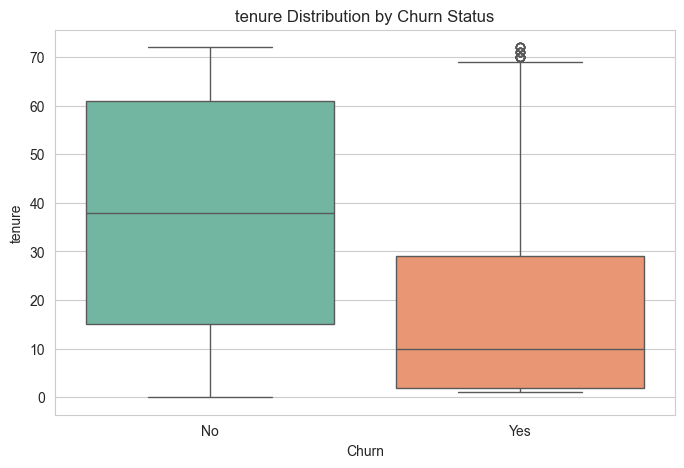

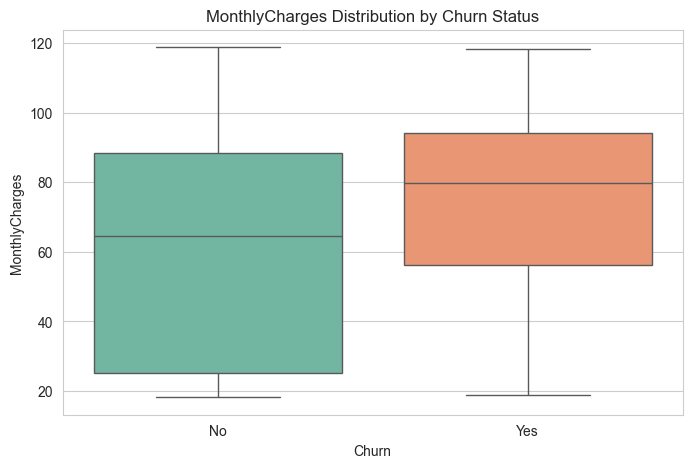

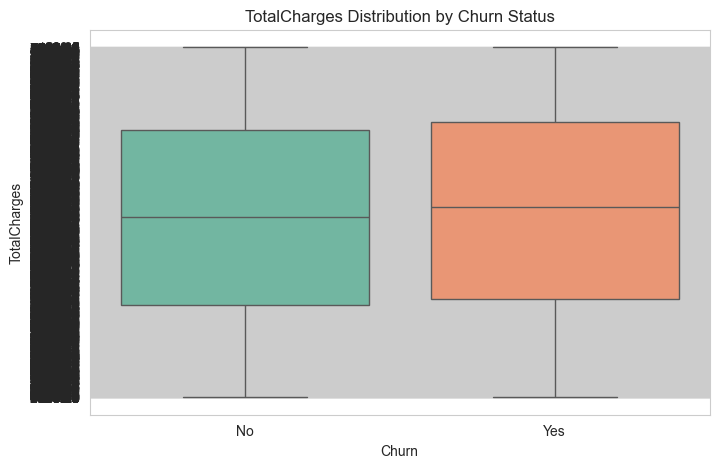

In [20]:
for feature in numerical_features:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=df,
        x='Churn',
        y=feature,
        hue='Churn',
        palette='Set2',
        legend=False
    )
    
    plt.title(f"{feature} Distribution by Churn Status")
    plt.xlabel("Churn")
    plt.ylabel(feature)
    
    plt.show()

In [21]:
print("TotalCharges data type:", df['TotalCharges'].dtype)

print("\nTotalCharges summary:")
print(df['TotalCharges'].describe())

print("\nNumber of zero TotalCharges values:", (df['TotalCharges'] == 0).sum())

TotalCharges data type: object

TotalCharges summary:
count     7043
unique    6531
top           
freq        11
Name: TotalCharges, dtype: object

Number of zero TotalCharges values: 0


## 4.1 Cleaning TotalCharges

During the initial exploration, TotalCharges was identified as an object data type rather than a numerical data type.

Because this column represents monetary values, it needs to be converted into a numerical format before it can be used in numerical analysis and machine learning.

The conversion process includes:

1. Removing leading and trailing whitespace
2. Replacing blank strings with missing values
3. Converting the column to a numerical data type
4. Checking the affected records to understand why values are missing

The 11 records with missing 'TotalCharges' values all ad a tenure with zero months. Since these customers had just started service and had not accumulated any charges, the missing values are replaced with zero.

This preserves the records while maintaining a logical interpretation of their billing information.

In [22]:
# convert TotalCharges to string first
df["TotalCharges"] = df["TotalCharges"].astype(str)

# remove leading/trailing whitespace and convert blanks to NaN
df["TotalCharges"] = df["TotalCharges"].str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors = "coerce"
)

# check the results
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nMissing TotalCharges values after conversion:")
print(df["TotalCharges"].isnull().sum())

# display affected records
display(
    df[df["TotalCharges"].isnull()][
        ["customerID", "TotalCharges", "tenure", "MonthlyCharges"]
    ]
)

TotalCharges data type:
float64

Missing TotalCharges values after conversion:
11


,customerID,TotalCharges,tenure,MonthlyCharges
488,4472-LVYGI,NaN,0,52.55
753,3115-CZMZD,NaN,0,20.25
936,5709-LVOEQ,NaN,0,80.85
1082,4367-NUYAO,NaN,0,25.75
1340,1371-DWPAZ,NaN,0,56.05
3331,7644-OMVMY,NaN,0,19.85
3826,3213-VVOLG,NaN,0,25.35
4380,2520-SGTTA,NaN,0,20.00
5218,2923-ARZLG,NaN,0,19.70
6670,4075-WKNIU,NaN,0,73.35


In [23]:
# examine tenure records with missing TotalCharges
print(
    df.loc[df["TotalCharges"].isnull(), "tenure"]
    .value_counts()
)

tenure
0    11
Name: count, dtype: int64


In [24]:
# fill missing TotalCharges values for new customers
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# verify cleaning
print("Remaining missing values:")
print(df["TotalCharges"].isnull().sum())

print("\nUpdated data types:")
print(df["TotalCharges"].dtype)

Remaining missing values:
0

Updated data types:
float64


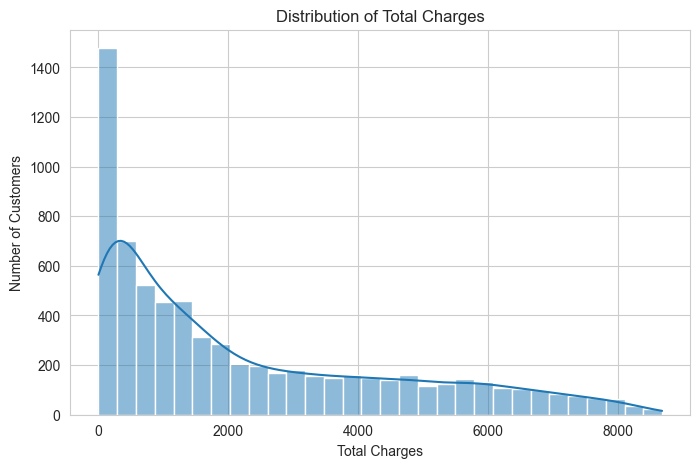

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='TotalCharges',
    bins=30,
    kde=True,
)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")

plt.show()

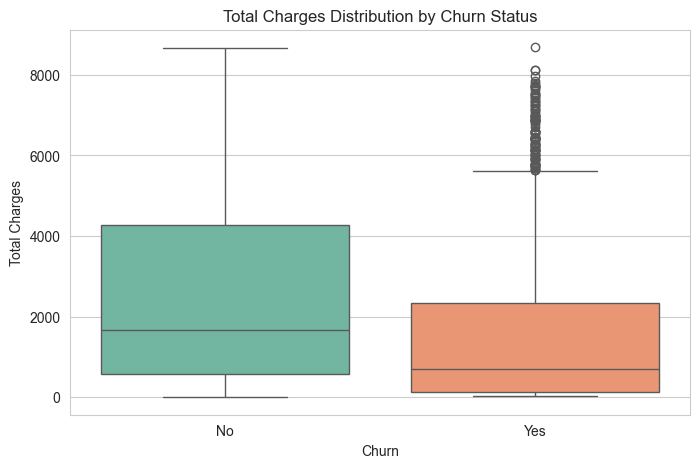

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title("Total Charges Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

### Initial EDA Findings

1. The dataset contains 7,043 customer records, with an overall churn rate of 26.54%.
2. Customers who churned had a substantially lower median tenure than customers who remained with the company.
3. Customers who churned had a higher median monthly charge than customers who remained.
4. The TotalCharges column initially contained 11 blank string values. These were converted to missing values and investigated before being handled. 
5. The dataset has a moderate class imbalance, which will be considered during model evaluation. 

In [27]:
# fill missing TotalCharges values with 0
# all affected customers have tenure of 0 months
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# verify the changes
print("Missing TotalCharges values:", df["TotalCharges"].isnull().sum())

print("\nTotalCharges data type:", df["TotalCharges"].dtype)

print("\nTotalCharges summary after cleaning:")
print(df["TotalCharges"].describe())

Missing TotalCharges values: 0

TotalCharges data type: float64

TotalCharges summary after cleaning:
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


### 5. Categorical Feature Analysis

Categorical features describe customer characteristics, subscribed services, account settings, and billing preferences.

To understand how these features relate to customer churn, the churn rate is calculated for each category within a feature.

The churn rate is calculated as:

Churn Rate = (Number of Churned Customers / Total Customers) x 100

Comparing these percentages helps identify categories associated with higher or lower customer churn.

These relationships may reveal useful predictors for the classification models and provide insight into potential customer retention strategies.

It is important to remember that these comparisons show associations and do not establish that a particular feature causes customers to churn. 

In [28]:
categorical_features = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "SeniorCitizen"
]

for feature in categorical_features:
    churn_rate = (
        df.groupby(feature, observed=True)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values(ascending=False)
    )
    
    print(f"\nChurn rate by {feature}:")
    display(churn_rate.round(2))


Churn rate by Contract:


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


Churn rate by PaymentMethod:


PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


Churn rate by InternetService:


InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

... (2 outputs left out)


Churn rate by TechSupport:


TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


Churn rate by SeniorCitizen:


SeniorCitizen
1    41.68
0    23.61
Name: Churn, dtype: float64

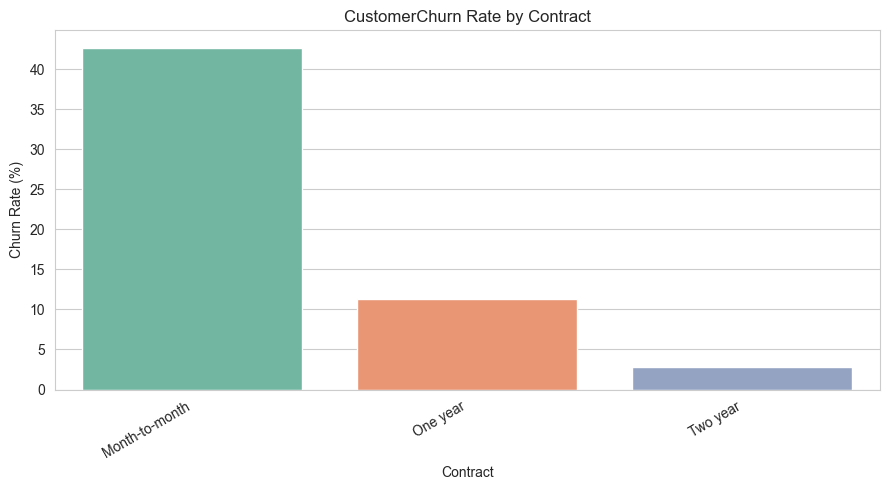

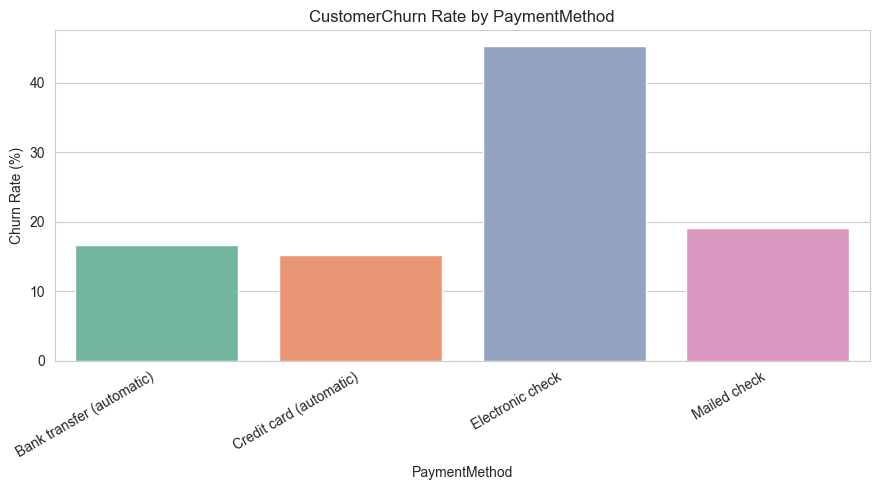

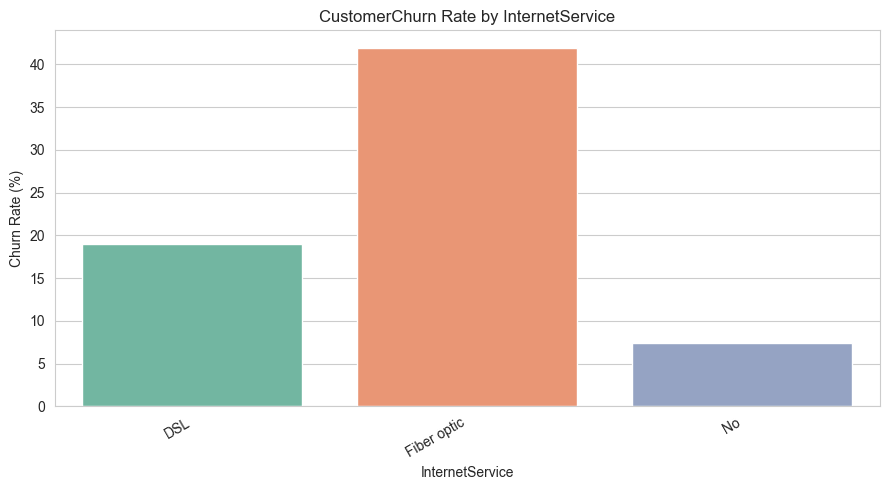

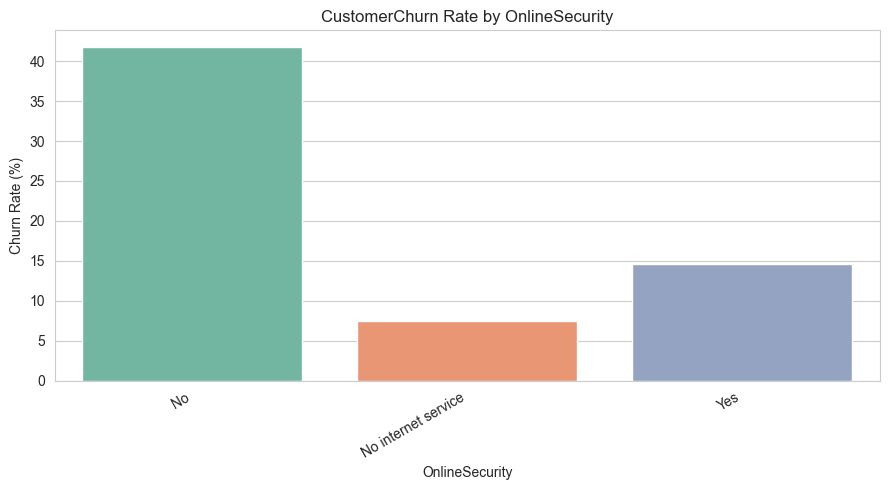

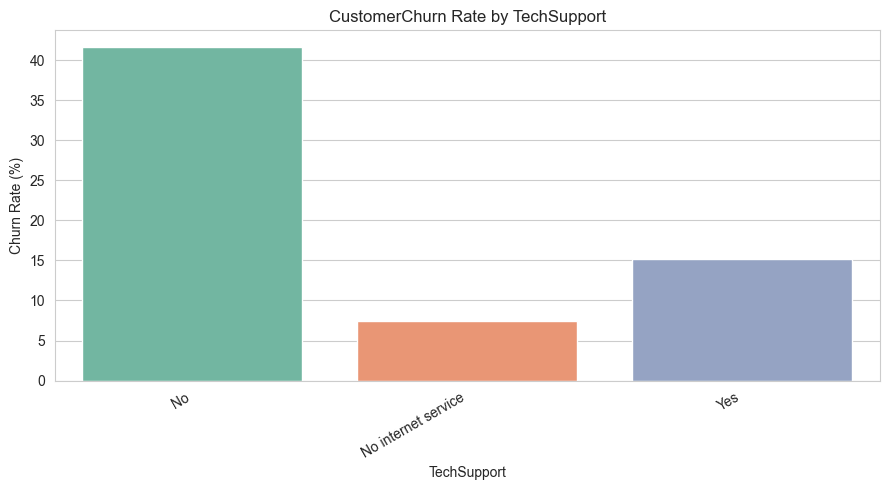

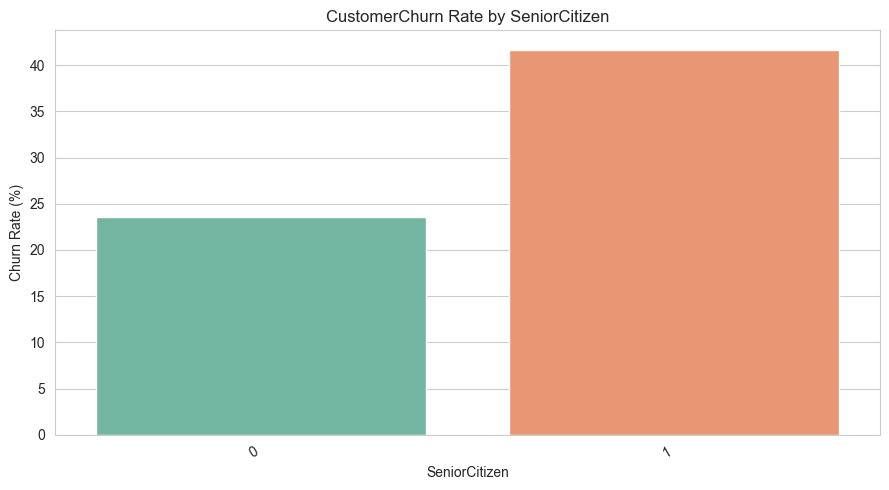

In [29]:
for feature in categorical_features:
    plt.figure(figsize=(9, 5))
    
    churn_rate = (
        df.groupby(feature, observed=True)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .reset_index(name="ChurnRate")
    )
    
    sns.barplot (
        data=churn_rate,
        x=feature,
        y="ChurnRate",
        hue=feature,
        palette='Set2',
        legend=False
    )
    
    plt.title(f"CustomerChurn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30, ha='right')
    
    plt.tight_layout()
    plt.show()

### Categorical Feature Analysis Findings

1. Contract type showed a strong association with churn. Month-to-month customers had a churn rate of 42.71%, compared to 2.83% for two-year contract customers.

2. Customers using electronic checks had the highest churn rate among payment methods at 45.29%.

3. Fiber optic customers had a churn rate of 41.89%, substantially higher than DSL customers at 18.96%.

4. Customers without online security or technical support had churn rates above 41%, compared to approximately 15% among customers with these services.

5. Senior citizens had a higher churn rate (41.68%) than non-senior citizens (23.61%).

These findings represent associations in the dataset and do not establish that any individual feature causes churn.

In [30]:
remaining_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling"
]

for feature in remaining_features:
    
    summary = (
        df.groupby(feature, observed=True)['Churn']
        .agg(
            total_customers="size",
            churned=lambda x: (x == 'Yes').sum()
        )
    )
    
    summary["churn_rate"] = (
        summary["churned"] / summary["total_customers"] * 100
    )
    
    print(f"\nChurn analysis by {feature}:")
    display(summary.round(2))


Churn analysis by gender:


,total_customers,churned,churn_rate
gender,,,
Female,3488,939,26.92
Male,3555,930,26.16



Churn analysis by Partner:


,total_customers,churned,churn_rate
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66



Churn analysis by Dependents:


,total_customers,churned,churn_rate
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45


... (10 outputs left out)


Churn analysis by StreamingMovies:


,total_customers,churned,churn_rate
StreamingMovies,,,
No,2785,938,33.68
No internet service,1526,113,7.40
Yes,2732,818,29.94



Churn analysis by PaperlessBilling:


,total_customers,churned,churn_rate
PaperlessBilling,,,
No,2872,469,16.33
Yes,4171,1400,33.57


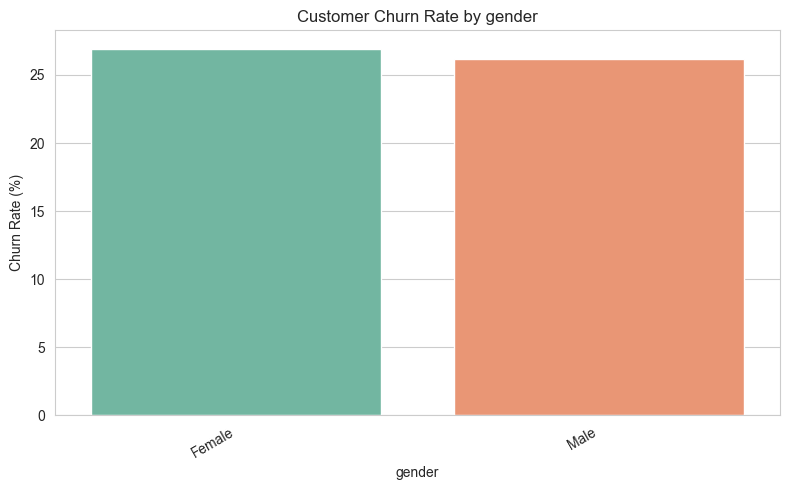

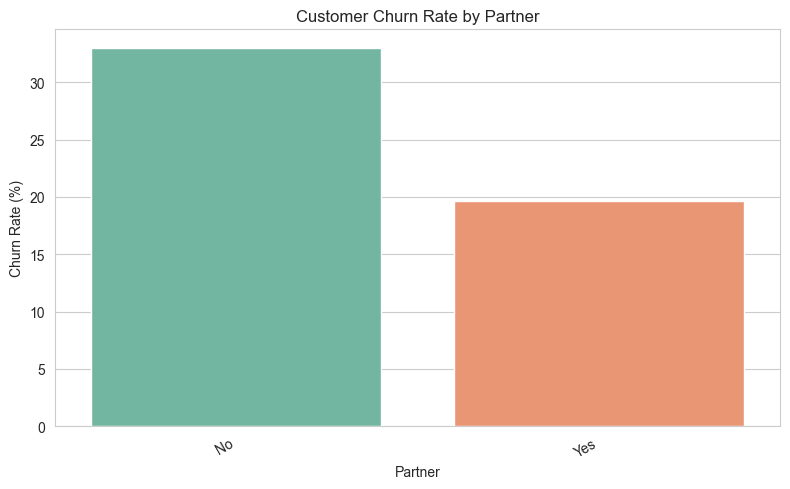

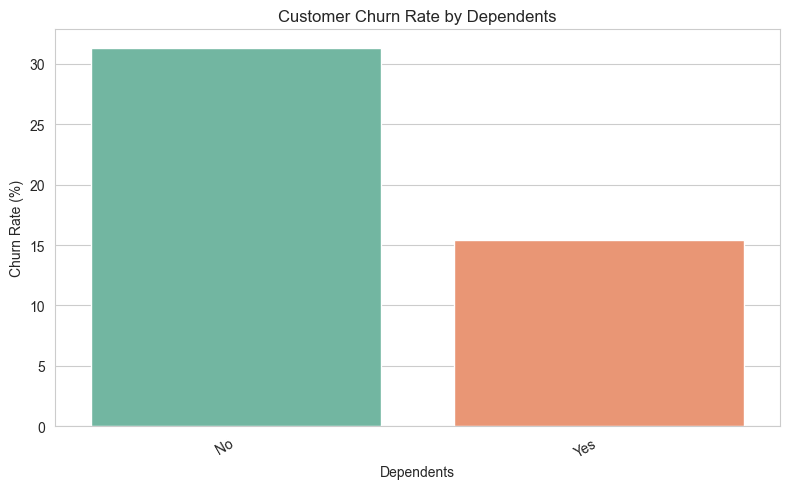

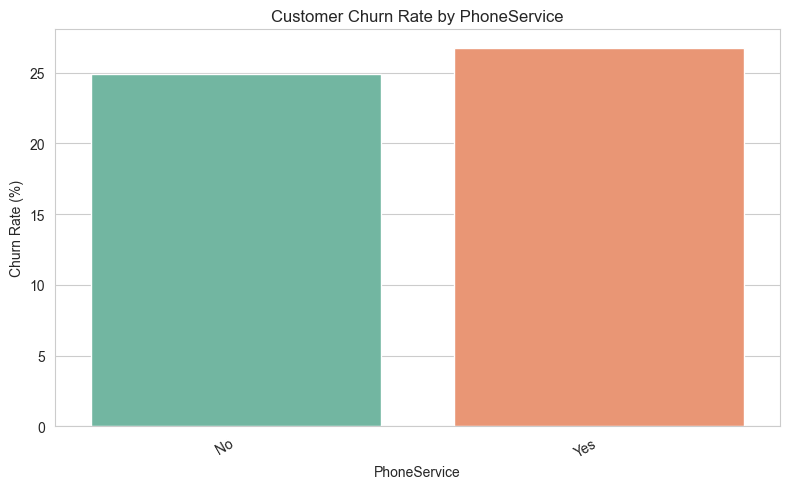

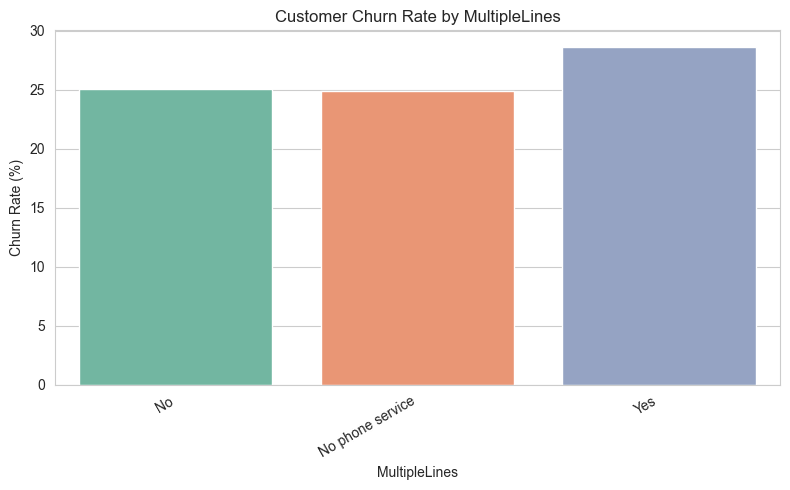

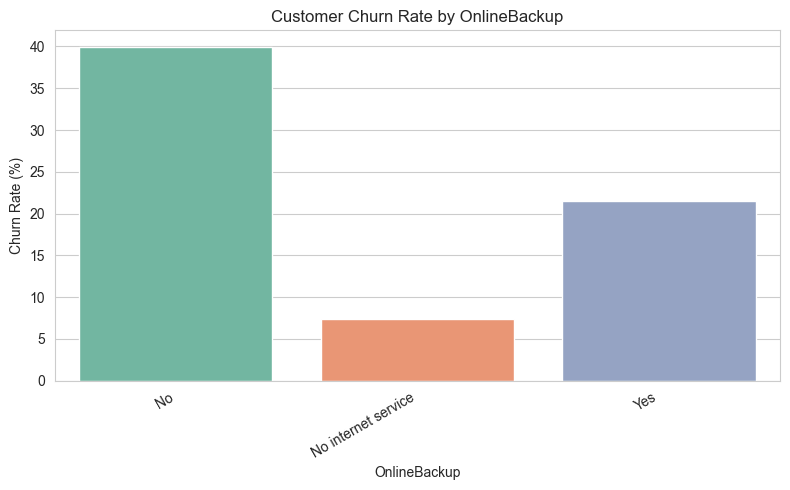

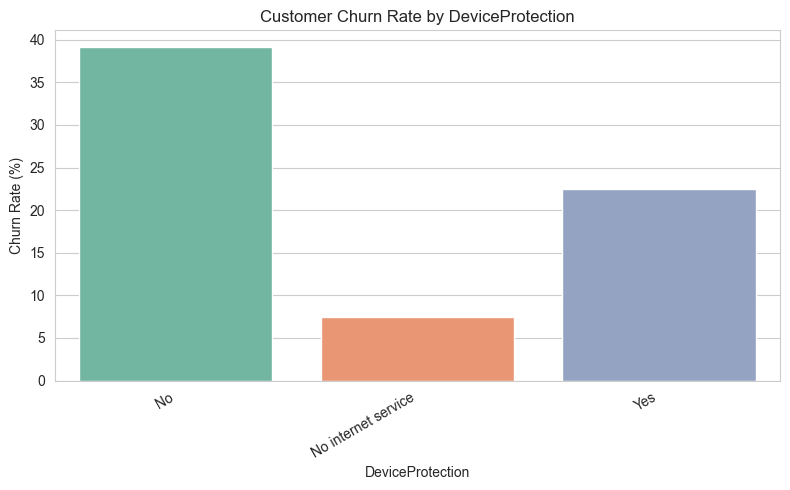

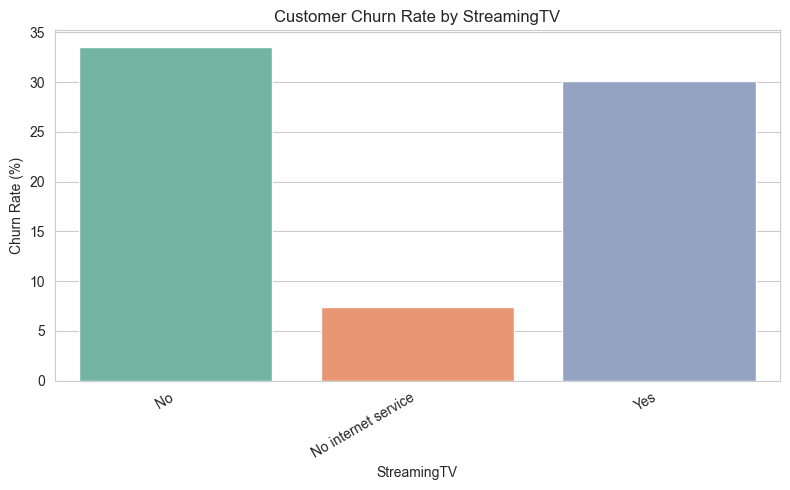

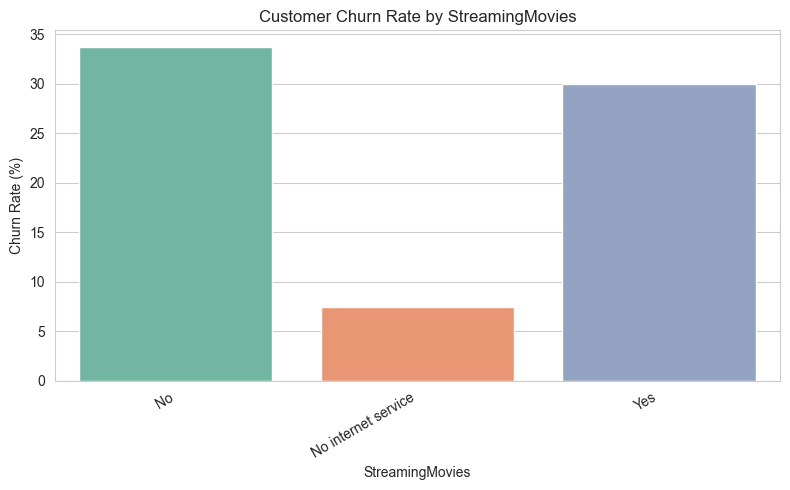

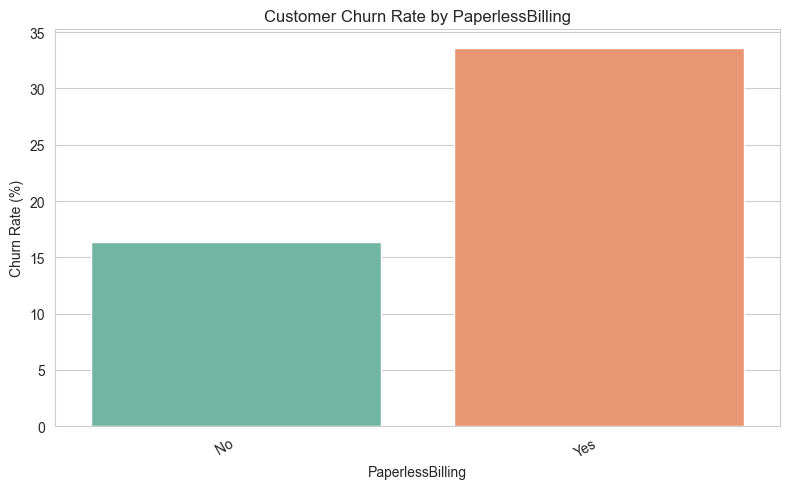

In [31]:
for feature in remaining_features:
    
    churn_rate = (
        df.groupby(feature, observed=True)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .reset_index(name="ChurnRate")
    )
    
    plt.figure(figsize=(8, 5))
    
    sns.barplot(
        data=churn_rate,
        x=feature,
        y="ChurnRate",
        hue=feature,
        palette='Set2',
        legend=False
    )
    
    plt.title(f"Customer Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30, ha='right')
    
    plt.tight_layout()
    plt.show()

### Additional Categorical Feature Findings

1. Gender showed very little difference in churn rates, with female customers at 26.92% and male customers at 26.16%

2. Customers without partners (32.96%) or dependents (31.26%) had higher churn rates than customers with partners (19.66%) or dependents (15.45%)

3. Phone service and multiple lines showed relatively small differences in churn rates

4. Customers without online backup or device protection had substantially higher churn rates than customers with these services

5. Streaming TV and movies showed smaller differences in churn rates

6. Customers with paperless billing had a churn rate of 33.57%, compared to 16.33% for customers without paperless billing

These patterns represent associations in the dataset and do no not establish causal relationships. 

### 6. Numerical Relationships and Correlation

After examining individual numerical features, the next step is the investigate how they relate to one another.

A correlation matrix is used to measure the strength and direction of linear relationships between numerical variables.

Correlation values range from -1 to +1:

- Values close to +1 indicate a strong positive relationship
- Values close to -1 indicate a strong negative relationship
- Values close to 0 indicate little to no linear relationship

The target variable is temporarily encoded numerically so its correlation with the numerical features can be examined.

This analysis helps identify potentially useful predictive features and relationships between predictors.

Correlation does not imply causation, and categorical relationships are not captures by this analysis.

In [32]:
# create a temporary numerical version of churn for correlation analysis
df["Churn_numeric"] = df["Churn"].map({"No": 0, "Yes": 1})

# select numerical columns for correlation analysis
numerical_df = df[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Churn_numeric"
    ]
]

# calculate correlation matrix
correlation_matrix = numerical_df.corr()

# display the correlation matrix
display(correlation_matrix.round(3))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_numeric
SeniorCitizen,1.000,0.017,0.220,0.103,0.151
tenure,0.017,1.000,0.248,0.826,-0.352
MonthlyCharges,0.220,0.248,1.000,0.651,0.193
TotalCharges,0.103,0.826,0.651,1.000,-0.198
Churn_numeric,0.151,-0.352,0.193,-0.198,1.000


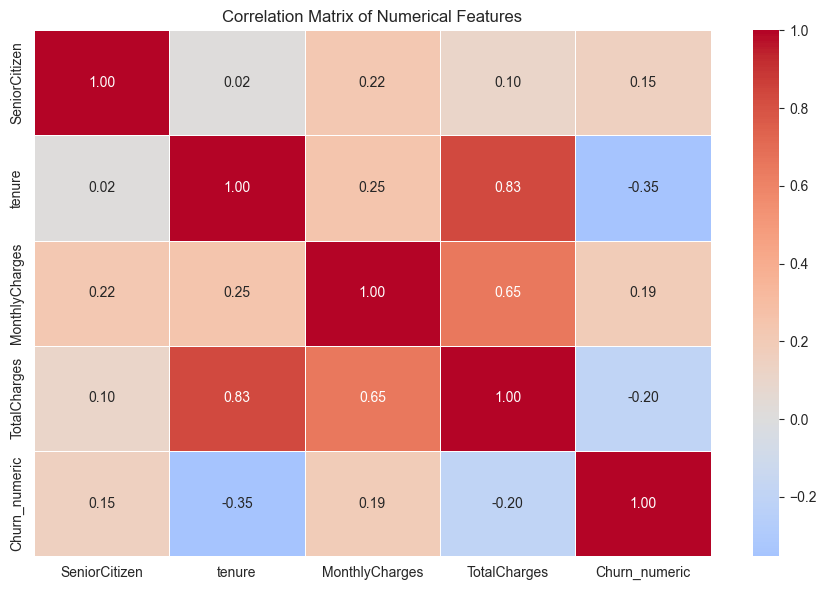

In [33]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

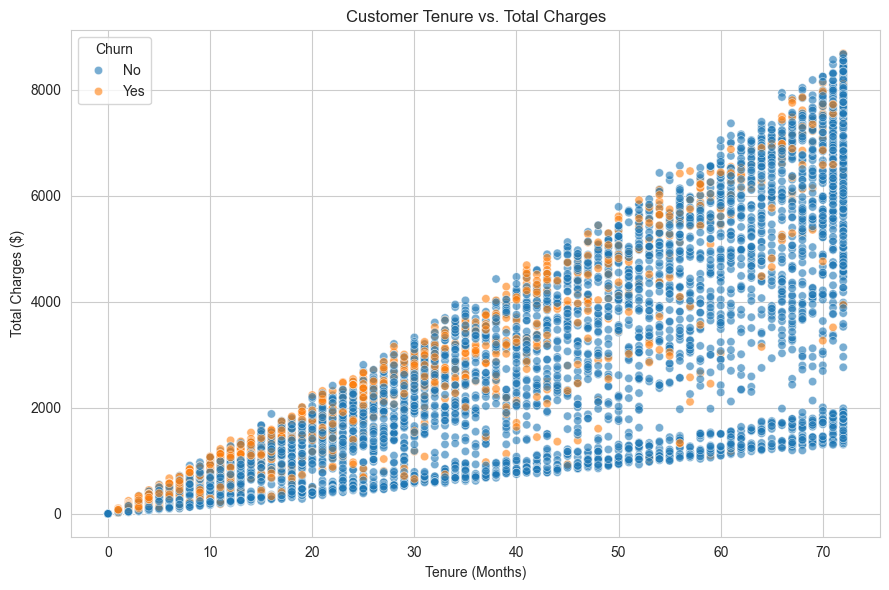

In [34]:
# relationship between tenure and total charges
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges",
    hue="Churn",
    alpha=0.6,
)

plt.title("Customer Tenure vs. Total Charges")  
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges ($)")

plt.tight_layout()
plt.show()

### Numerical Feature Relationships

The correlation analysis identified customer tenure as the numerical feature most strongly associated with churn, with a correlation of -0.352. This suggests that customers with longer relationships with the company are less likely to leave.

MonthlyCharges had a weak positive correlation with churn (0.193), while TotalCharges had a weak negative correlation (10.198). The negative relationship with TotalCharges may partly reflect the strong positive correlation between tenure and TotalCharges (0.826).

The scatter plot also demonstrated that total charges generally increase with customer tenure. Churned customers appeared more concentrated among customers with shorter tenures.

These findings suggest that customer tenure, monthly charges, and accumulated charges may provide useful predictive information for the classification models. 

In [35]:
# remove temporary target encoding column
df.drop(columns=["Churn_numeric"], inplace=True)

print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### 7. EDA Summary and Key Findings

##### Dataset Overview

The IDM Telco Customer Churn dataset contains 7,043 customer records and 21 columns describing customer demographics, subscribed services, account information, and billing behavior.

The target variable, `Churn`, indicates whether a customer discontinued their service. Of the 7,043 customers:

- 5,174 (73.46%) did not churn
- 1,869 (26.54%) churned

This indicates a moderate class imbalance, which will be considered when selecting and evaluating classification models.

During data cleaning, `TotalCharges` was converted from an object to a numerical data type. Eleven blank values were identified, all belonging to customers with zero months of tenure. These values were replaced with zero because those customers had not accumulated any charges.

##### Key Findings

The exploratory analysis revealed several patterns associated with customer churn:

##### 1. Contract Type

Customers with month-to-month contracts had a churn rate of 42.71%, compared to 11.7% for one-year contracts and 2.83% for two-years contracts. Contract type appears to be an important feature for predicting churn.

##### 2. Customer Tenure

Tenure had the strongest numerical correlation with churn (-0.352). Customers with shorter relationships with the company were more likely to discontinue service.

##### 3. Payment Method

Customers paying by electronic check had a churn rate of 45.29%, considerably higher than customers using automatic bank transfers (16.71%) or automatic credit card payments (15.24%).

##### 4. Additional Services

Customers without OnlineSecurity and TechSupport had churn rates of 41.77% and 41.64%, respectively. Customers without OnlineBackup and DeviceProtection also demonstrated higher churn rates than customers subscribed to those services.

##### 5. Customer Characteristics

Customers without partners or dependents had higher churn rates than customers with partners or dependents. Senior citizens also demonstrated a higher churn rate (41.68%) than non-senior customers (23.61%).

##### 6. Billing Information

MonthlyCharges had a weak positive correlation with churn (0.193), while TotalCharges had a weak negative (-0.198). TotalCharges was strongly correlated with tenure (0.826), which is expected because customers generally accumulate more charges over longer periods of service.

#### Implications for Machine Learning

These findings help guide the next stage of the project:

- Contract type, tenure, payment method, and subscribed services will be retained as potential predictive features
- Both numerical and categorical variables will need appropriate preprocessing before model training
- Categorical variables will require encoding so they can be used by classification algorithms
- The moderate class imbalance means accuracy alone will not be sufficient for evaluating model performance
- Precision, recall, F1-score, ROC-AUC, and confusion matrices will be used to compare models and understand their ability to identify customers who churn

If is important to recognize that the relationships identified during EDA represent associations rather than causal relationships. Further analysis through model evaluation and feature importance will help determine which features contribute most to predictive performance.

#### Conclusion

The exploratory data analysis identified several meaningful patterns in customer churn, particularly around contract type, customer tenure, payment methods, and additional services.

These findings provide a foundation for the preprocessing and modeling stages. The next phase will focus on preparing the dataset for machine learning separating predictors from the target variable, encoding categorical features, splitting the data into training and testing sets, and building a reusable preprocessing pipeline.